# Chatbot Usada Taru Pramana: IndoBERT

## 0. Instalasi & import library

In [ ]:
import os, re, json, random, shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, EarlyStoppingCallback)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
pd.set_option("display.max_colwidth", 100)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


# 1. Eksplorasi Data

### 1.1 Load data

In [ ]:
DATA_DIR = "Dataset"   # folder berisi train.csv, valid.csv, test.csv

# Di Colab: upload file kalau belum ada
if not os.path.exists(f"{DATA_DIR}/train.csv"):
    from google.colab import files
    os.makedirs(DATA_DIR, exist_ok=True)
    for nama, isi in files.upload().items():
        open(os.path.join(DATA_DIR, nama), "wb").write(isi)

KOLOM = ["Konteks", "Pertanyaan", "Jawaban"]
train_df = pd.read_csv(f"{DATA_DIR}/train.csv", encoding="utf-8-sig")[KOLOM]
val_df   = pd.read_csv(f"{DATA_DIR}/valid.csv", encoding="utf-8-sig")[KOLOM]
test_df  = pd.read_csv(f"{DATA_DIR}/test.csv",  encoding="utf-8-sig")[KOLOM]

# buang baris kosong (file CSV berisi baris tanpa isi di bagian bawah)
train_df = train_df.dropna(subset=["Pertanyaan", "Jawaban"]).reset_index(drop=True)
val_df   = val_df.dropna(subset=["Pertanyaan", "Jawaban"]).reset_index(drop=True)
test_df  = test_df.dropna(subset=["Pertanyaan", "Jawaban"]).reset_index(drop=True)

for df in (train_df, val_df, test_df):
    for k in KOLOM:
        df[k] = df[k].fillna("").astype(str).str.strip()

print("Train / Validation / Test:", len(train_df), "/", len(val_df), "/", len(test_df))
train_df.head()

Saving valid.csv to valid.csv
Saving train.csv to train.csv
Saving test.csv to test.csv
Train / Validation / Test: 1050 / 150 / 300


,Konteks,Pertanyaan,Jawaban
0,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Apa khasiat kayu santen menurut lontar Usadha Taru Pramana?,Kayu santen berkhasiat untuk meredakan sakit maag.
1,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Penyakit apa yang bisa diredakan dengan kayu santen?,Kayu santen berkhasiat untuk meredakan sakit maag.
2,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Kayu santen berkhasiat untuk apa dalam lontar Taru Pramana?,Kayu santen berkhasiat untuk meredakan sakit maag.
3,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Apa fungsi kayu santen sebagai tanaman obat Bali?,Kayu santen berkhasiat untuk meredakan sakit maag.
4,"Dalam lontar usadha Taru Pramana, kayu santen tercatat sebagai tanaman obat tradisional yang ber...",Manfaat kayu santen sebagai obat tradisional apa?,Kayu santen berkhasiat untuk meredakan sakit maag.


### 1.2 Cek kebocoran data

In [ ]:
norm = lambda s: s.str.lower().str.strip()
q_train = set(norm(train_df["Pertanyaan"]))
print("Jawaban unik di train          :", train_df["Jawaban"].nunique())
print("Semua jawaban test ada di train:", set(test_df.Jawaban) <= set(train_df.Jawaban))
print("Pertanyaan val yang sama dengan train :", norm(val_df["Pertanyaan"]).isin(q_train).sum())
print("Pertanyaan test yang sama dengan train:", norm(test_df["Pertanyaan"]).isin(q_train).sum())

Jawaban unik di train          : 150
Semua jawaban test ada di train: True
Pertanyaan val yang sama dengan train : 0
Pertanyaan test yang sama dengan train: 0


# 2. Preprocessing

### Preprocessing 1: Case folding

In [ ]:
def case_folding(text):
    return text.lower()

for df in (train_df, val_df, test_df):
    df["q"] = df["Pertanyaan"].apply(case_folding)

train_df[["Pertanyaan", "q"]].head(3)

,Pertanyaan,q
0,Apa khasiat kayu santen menurut lontar Usadha Taru Pramana?,apa khasiat kayu santen menurut lontar usadha taru pramana?
1,Penyakit apa yang bisa diredakan dengan kayu santen?,penyakit apa yang bisa diredakan dengan kayu santen?
2,Kayu santen berkhasiat untuk apa dalam lontar Taru Pramana?,kayu santen berkhasiat untuk apa dalam lontar taru pramana?


### Preprocessing 2: Cleaning

In [ ]:
def cleaning(text):
    text = re.sub(r"[-–—/]", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

for df in (train_df, val_df, test_df):
    df["q"] = df["q"].apply(cleaning)

train_df[["Pertanyaan", "q"]].head(3)

,Pertanyaan,q
0,Apa khasiat kayu santen menurut lontar Usadha Taru Pramana?,apa khasiat kayu santen menurut lontar usadha taru pramana
1,Penyakit apa yang bisa diredakan dengan kayu santen?,penyakit apa yang bisa diredakan dengan kayu santen
2,Kayu santen berkhasiat untuk apa dalam lontar Taru Pramana?,kayu santen berkhasiat untuk apa dalam lontar taru pramana


### Preprocessing 3: Normalisasi kata tidak baku

In [ ]:
kamus_normalisasi = {
    "gmn": "bagaimana", "gimana": "bagaimana", "gmana": "bagaimana",
    "bikin": "membuat", "dibikin": "dibuat", "bikinnya": "membuatnya",
    "gak": "tidak", "ga": "tidak", "gk": "tidak", "nggak": "tidak", "tdk": "tidak",
    "aja": "saja", "yg": "yang", "dgn": "dengan", "utk": "untuk",
    "dipake": "dipakai", "pake": "pakai", "ngobatin": "mengobati", "ngambil": "mengambil",
    "ngejelasin": "menjelaskan", "disimpen": "disimpan", "dapet": "dapat",
    "kulkas": "lemari es", "mencret": "diare", "serai": "sereh",
}

def normalisasi(text):
    return " ".join(kamus_normalisasi.get(w, w) for w in text.split())

def preprocessing(text):
    return normalisasi(cleaning(case_folding(text)))

for df in (train_df, val_df, test_df):
    df["q"] = df["Pertanyaan"].apply(preprocessing)

contoh = train_df[train_df["Pertanyaan"].str.lower().str.contains(r"\b(?:gimana|bikin|aja|gak)\b")]
contoh[["Pertanyaan", "q"]].head()

,Pertanyaan,q
13,isi ajaran taru pramana soal tumbuhan obat apa aja,isi ajaran taru pramana soal tumbuhan obat apa saja
20,kayu santen bisa buat radang lambung gak,kayu santen bisa buat radang lambung tidak
32,cara bikin usadha kayu santen di rumah,cara membuat usadha kayu santen di rumah
75,cara pakai boreh kencur gimana,cara pakai boreh kencur bagaimana
101,minyak cem-ceman dipakai gimana buat rambut dan aromaterapi,minyak cem ceman dipakai bagaimana buat rambut dan aromaterapi


### Preprocessing 4: Tokenisasi IndoBERT

In [ ]:
MODEL_NAME = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

contoh_kalimat = train_df["q"].iloc[0]
enc = tokenizer(contoh_kalimat)
print("Kalimat   :", contoh_kalimat)
print("Token     :", tokenizer.convert_ids_to_tokens(enc["input_ids"]))
print("Nomor     :", enc["input_ids"])

panjang = [len(tokenizer(q)["input_ids"]) for q in train_df["q"]]
print("\nPanjang token terpanjang di train:", max(panjang))

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Kalimat   : apa khasiat kayu santen menurut lontar usadha taru pramana
Token     : ['[CLS]', 'apa', 'khasiat', 'kayu', 'sant', '##en', 'menurut', 'lontar', 'usa', '##dh', '##a', 'tar', '##u', 'pram', '##ana', '[SEP]']
Nomor     : [2, 387, 5527, 2164, 3136, 9, 807, 27715, 11276, 10219, 30354, 1379, 30360, 4623, 192, 3]

Panjang token terpanjang di train: 22


### Preprocessing 5: Padding dan attention mask

In [ ]:
MAX_LEN = 48

enc = tokenizer(contoh_kalimat, padding="max_length", truncation=True, max_length=MAX_LEN)
print("input_ids     :", enc["input_ids"])
print("attention_mask:", enc["attention_mask"])

input_ids     : [2, 387, 5527, 2164, 3136, 9, 807, 27715, 11276, 10219, 30354, 1379, 30360, 4623, 192, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


### Preprocessing 6: Label encoding

In [ ]:
daftar_jawaban = list(dict.fromkeys(train_df["Jawaban"]))
jawaban2id = {j: i for i, j in enumerate(daftar_jawaban)}
id2jawaban = {i: j for j, i in jawaban2id.items()}
NUM_CLASSES = len(jawaban2id)

for df in (train_df, val_df, test_df):
    df["label"] = df["Jawaban"].map(jawaban2id)

id2konteks = train_df.drop_duplicates("Jawaban").set_index("label")["Konteks"].to_dict()

print("Jumlah kelas:", NUM_CLASSES)
print("Contoh: kelas 0 →", id2jawaban[0][:80], "...")

Jumlah kelas: 150
Contoh: kelas 0 → Kayu santen berkhasiat untuk meredakan sakit maag. ...


### Membuat dataset untuk training
Setiap baris berisi `input_ids`, `attention_mask`, dan `labels`.

In [ ]:
class DatasetPertanyaan(torch.utils.data.Dataset):
    def __init__(self, df):
        self.encodings = tokenizer(df["q"].tolist(), padding="max_length",
                                   truncation=True, max_length=MAX_LEN)
        self.labels = df["label"].tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        item = {key: torch.tensor(nilai[i]) for key, nilai in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[i])
        return item

train_data = DatasetPertanyaan(train_df)
val_data   = DatasetPertanyaan(val_df)
test_data  = DatasetPertanyaan(test_df)
print("Jumlah data:", len(train_data), len(val_data), len(test_data))

Jumlah data: 1050 150 300


# 3. Model IndoBERT

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label={i: str(i) for i in range(NUM_CLASSES)},
    label2id={str(i): i for i in range(NUM_CLASSES)},
)
print("Jumlah parameter:", f"{sum(p.numel() for p in model.parameters()):,}")
print(model.classifier)

[transformers] You passed `num_labels=150` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Jumlah parameter: 124,556,694
Linear(in_features=768, out_features=150, bias=True)


# 4. Training

In [ ]:
def hitung_metrik(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": p, "recall": r, "f1": f1}

def metrik_trainer(eval_pred):
    logits, labels = eval_pred
    return hitung_metrik(labels, np.argmax(logits, axis=1))

In [ ]:
EPOCHS = 30
BATCH_SIZE = 16
LEARNING_RATE = 4e-5
langkah_total = EPOCHS * int(np.ceil(len(train_data) / BATCH_SIZE))

args = TrainingArguments(
    output_dir="checkpoint_indobert",
    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=64,
    warmup_steps=int(0.1 * langkah_total),
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    save_total_limit=1,
    save_only_model=True,
    seed=SEED,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_data,
    eval_dataset=val_data,
    compute_metrics=metrik_trainer,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=5)],
)
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,5.047006,4.899567,0.040000,0.012130,0.040000,0.015639
2,4.645972,4.093823,0.473333,0.335730,0.473333,0.371672
3,3.527091,2.632911,0.813333,0.743333,0.813333,0.764222
4,2.197401,1.566942,0.873333,0.822778,0.873333,0.838222
5,1.287958,1.000240,0.880000,0.832778,0.880000,0.847111
6,0.755563,0.604117,0.946667,0.920000,0.946667,0.928889
7,0.427719,0.409313,0.940000,0.910000,0.940000,0.920000
8,0.244557,0.337728,0.926667,0.895000,0.926667,0.904889
9,0.142975,0.245568,0.953333,0.930000,0.953333,0.937778
10,0.085266,0.233920,0.946667,0.920000,0.946667,0.928889


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (10 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1188, training_loss=1.0345056855718697, metrics={'train_runtime': 316.2414, 'train_samples_per_second': 59.764, 'train_steps_per_second': 3.757, 'total_flos': 466819402694400.0, 'train_loss': 1.0345056855718697, 'epoch': 18.0})

### Grafik loss & akurasi

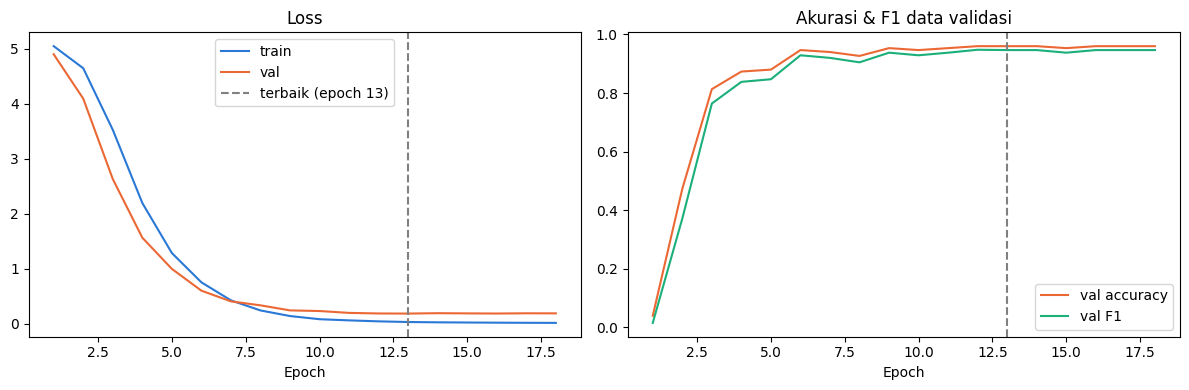

Epoch terbaik: 13 | val_loss: 0.1878
Total epoch dijalankan: 18


Akurasi train: 1.0000 | val: 0.9600 | selisih (indikasi overfitting): 0.0400


In [ ]:
log = pd.DataFrame(trainer.state.log_history)
train_loss = log.dropna(subset=["loss"]).groupby("epoch")["loss"].last()
val_log = log.dropna(subset=["eval_loss"]).set_index("epoch")
terbaik = val_log["eval_loss"].idxmin()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(train_loss.index, train_loss.values, label="train", color="#2a78d6")
ax[0].plot(val_log.index, val_log["eval_loss"], label="val", color="#eb6834")
ax[0].axvline(terbaik, ls="--", c="gray", label=f"terbaik (epoch {terbaik:.0f})")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(val_log.index, val_log["eval_accuracy"], label="val accuracy", color="#eb6834")
ax[1].plot(val_log.index, val_log["eval_f1"], label="val F1", color="#1baf7a")
ax[1].axvline(terbaik, ls="--", c="gray")
ax[1].set_title("Akurasi & F1 data validasi"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"Epoch terbaik: {terbaik:.0f} | val_loss: {val_log.loc[terbaik, 'eval_loss']:.4f}")
print(f"Total epoch dijalankan: {val_log.index.max():.0f}")

# cek overfitting: bandingkan akurasi train dan validasi dengan bobot terbaik
acc_train = hitung_metrik(train_df["label"], trainer.predict(train_data).predictions.argmax(1))["accuracy"]
acc_val   = hitung_metrik(val_df["label"], trainer.predict(val_data).predictions.argmax(1))["accuracy"]
print(f"Akurasi train: {acc_train:.4f} | val: {acc_val:.4f} | selisih (indikasi overfitting): {acc_train - acc_val:.4f}")

# 5. Evaluasi

### Metrik pada data test

In [ ]:
logits_test = trainer.predict(test_data).predictions
prob_test = torch.softmax(torch.tensor(logits_test), dim=1).numpy()
pred_test = prob_test.argmax(axis=1)
y_test = test_df["label"].values

m = hitung_metrik(y_test, pred_test)
skor_test = {"Accuracy": m["accuracy"], "Precision (macro)": m["precision"],
             "Recall (macro)": m["recall"], "F1 (macro)": m["f1"]}
display(pd.DataFrame([skor_test], index=["Test"]).round(4))

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Test,0.9667,0.97,0.9667,0.9624


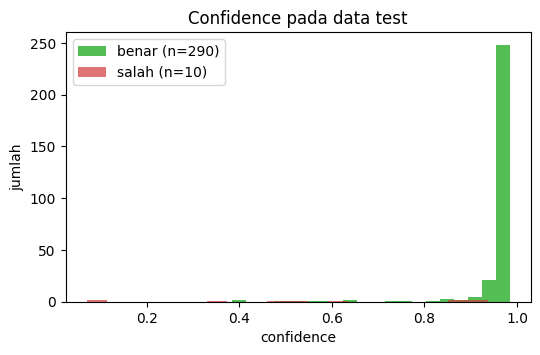

Rata-rata confidence benar: 0.956 | salah: 0.582


In [ ]:
conf = prob_test.max(axis=1)
benar = pred_test == y_test
plt.figure(figsize=(6, 3.5))
plt.hist(conf[benar], bins=20, alpha=0.7, label=f"benar (n={benar.sum()})", color="#0ca30c")
plt.hist(conf[~benar], bins=20, alpha=0.7, label=f"salah (n={(~benar).sum()})", color="#d03b3b")
plt.xlabel("confidence"); plt.ylabel("jumlah"); plt.legend(); plt.title("Confidence pada data test")
plt.show()
print(f"Rata-rata confidence benar: {conf[benar].mean():.3f} | "
      f"salah: {conf[~benar].mean() if (~benar).any() else float('nan'):.3f}")

# 6. Analisis prediksi

In [ ]:
analisis = pd.DataFrame({
    "Pertanyaan": test_df["Pertanyaan"],
    "Jawaban benar": test_df["Jawaban"],
    "Prediksi": [id2jawaban[i] for i in pred_test],
    "Confidence": conf.round(3),
    "Benar": benar,
})
print(f"Benar {benar.sum()} dari {len(analisis)} pertanyaan")
print("\nContoh prediksi BENAR:")
display(analisis[analisis["Benar"]].sample(5, random_state=SEED))

Benar 290 dari 300 pertanyaan

Contoh prediksi BENAR:


,Pertanyaan,Jawaban benar,Prediksi,Confidence,Benar
88,Mengapa biji saga beracun?,"Biji saga harus dihindari karena mengandung abrin, yaitu senyawa beracun yang dapat membahayakan...","Biji saga harus dihindari karena mengandung abrin, yaitu senyawa beracun yang dapat membahayakan...",0.982,True
266,Gendongan itu penyakit apa?,Gendongan adalah bengkak yang terasa sakit di belakang telinga dekat pangkal geraham. Keluhan in...,Gendongan adalah bengkak yang terasa sakit di belakang telinga dekat pangkal geraham. Keluhan in...,0.978,True
48,daun jambu biji bisa buat diare gak,"Daun jambu biji dimanfaatkan secara tradisional untuk membantu mengatasi diare, peradangan, dan ...","Daun jambu biji dimanfaatkan secara tradisional untuk membantu mengatasi diare, peradangan, dan ...",0.942,True
179,Bagaimana resep tradisional nangka untuk menyembuhkan mual/nyenyeb?,Digunakan 3 helai daun nangka dumlada dan 11 biji merica yang dibalurkan langsung pada area ulu ...,Digunakan 3 helai daun nangka dumlada dan 11 biji merica yang dibalurkan langsung pada area ulu ...,0.979,True
147,Penyakit apa yang dapat disembuhkan dengan baluran kayu bila?,Seluruh bagian kayu bila dihaluskan untuk dijadikan odak (baluran) dengan menambahkan campuran k...,Seluruh bagian kayu bila dihaluskan untuk dijadikan odak (baluran) dengan menambahkan campuran k...,0.975,True


In [ ]:
print("Semua prediksi SALAH:")
analisis[~analisis["Benar"]]

Semua prediksi SALAH:


,Pertanyaan,Jawaban benar,Prediksi,Confidence,Benar
12,Bentuk ramuan loloh don kayu manis seperti apa?,Loloh adalah ramuan tradisional berbentuk cair yang diminum.,"Bahan yang digunakan adalah daun katuk atau don kayu manis, bawang merah, air matang, dan garam....",0.504,False
25,Peran bahan-bahan dalam ramuan minyak cem-ceman,Daun mangkokan dikenal membantu merangsang pertumbuhan dan memperkuat akar rambut. Minyak kelapa...,"Minyak cem-ceman digunakan secara tradisional untuk memberikan kelembapan dan kilau pada rambut,...",0.346,False
43,Usadha Seleguih dipakai dengan cara apa?,Oleskan ramuan secara merata pada luka ringan atau bagian kulit yang gatal akibat gigitan serang...,Usadha Seleguih adalah ramuan tradisional Bali yang digunakan untuk membantu merawat luka ringan...,0.894,False
79,gel lidah buaya diambil gimana,"Pilih daun lidah buaya yang segar, cuci hingga bersih, lalu kupas kulit luarnya. Ambil gel benin...",Oleskan gel pada area kulit yang membutuhkan dan biarkan selama 20–30 menit. Bilas jika diperluk...,0.537,False
210,Bahan apa saja yang dicampur dengan daun kelor untuk obat mata?,Daun kelor dicampur dengan jeruk nipis dan garam hitam atau uyah areng. Campuran kemudian disari...,"Daun kelor dicampur dengan air jeruk linglang dan uyah areng yang digilas, kemudian diperas, dis...",0.938,False
218,Kayu jamu biji berkhasiat untuk penyakit apa?,Kayu jamu biji atau sotong digunakan secara tradisional untuk mising atau diare pada anak-anak d...,"Pucuk daun pohon sotong diulek bersama 3 biji ketumbar bolong dan asam ireng, kemudian ditaruh d...",0.889,False
219,"Kalau punya pohon jambu biji di rumah, bisa buat obat apa saja?",Kayu jamu biji atau sotong digunakan secara tradisional untuk mising atau diare pada anak-anak d...,Buah jambu biji membantu memenuhi kebutuhan serat dan vitamin C serta mengandung antioksidan. Ak...,0.625,False
222,Pule untuk obat hangus pakai bagian apa?,Bagian pule atau pole yang digunakan adalah pucuk daunnya. Pucuk tersebut menjadi bahan ramuan t...,Loloh pohon pule dicampur dengan nyuh gula matunu (kelapa dan gula yang dipanggang) untuk mereda...,0.931,False
275,Tolong jelaskan cara mengolah daun Morus alba untuk sakit tenggorokan,"Daun murbai dicampur dengan air panas, kemudian didinginkan. Daun diremas-remas lalu disaring, d...","Biji buah brotowali yang sudah masak dikupas, diongseng (nyahnyah), lalu ditumbuk menjadi serbuk...",0.089,False
299,Daun Tagetes erecta dicampur apa untuk mengobati borok?,Daun gemitir dicampur dengan tembakau dan gamping atau pamor. Ketiga bahan diulek hingga halus u...,Daun kelor dicampur dengan jeruk nipis dan garam hitam atau uyah areng. Campuran kemudian disari...,0.070,False


# 7. Mencoba chatbot

In [ ]:
BATAS_YAKIN = 0.5
model_final = trainer.model.to(DEVICE).eval()

def tanya(pertanyaan):
    inputs = tokenizer(preprocessing(pertanyaan), truncation=True, max_length=MAX_LEN,
                       return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        prob = torch.softmax(model_final(**inputs).logits, dim=1)[0]
    kelas = int(prob.argmax())
    confidence = float(prob[kelas])

    if confidence < BATAS_YAKIN:
        return {"jawaban": "Maaf, saya belum memiliki informasi tentang hal itu.",
                "konteks": None, "confidence": round(confidence, 4)}
    return {"jawaban": id2jawaban[kelas], "konteks": id2konteks[kelas], "confidence": round(confidence, 4)}

for q in ["mata aku sakit, bagusnya pakai tanaman apa",
          "Apa arti memedak?",
          "Apa itu tanaman?"]:
    print("Q:", q)
    print("A:", tanya(q), "\n")

Q: mata aku sakit, bagusnya pakai tanaman apa
A: {'jawaban': 'Daun kelor dicampur dengan jeruk nipis dan garam hitam atau uyah areng. Campuran kemudian disaring dan diendapkan dalam pengolahan ramuan tradisional.', 'konteks': 'Kayu kelor Moringa oleifera Mengobati sakit mata Daun kelor (t) dicampur dengan jeruk nipis ( juwuk lengis) ditambah sedikit garam ireng (uyah areng) kemudian disaring dan diendapkan, setelah itu baru diteteskan pada mata (netra).', 'confidence': 0.6796} 

Q: Apa arti memedak?
A: {'jawaban': 'Memedak berarti haus. Pada penggunaan pohon piling, istilah ini berkaitan dengan panas yang disertai rasa haus terus-menerus.', 'konteks': 'Pohon piling Abrus precatorius Obat panas yang selalu memedak (haus) Akar piling (t) dicampur dengan kelapa muda(bungkak nyuh mulung ) dibuat jamu (loloh).', 'confidence': 0.9828} 

Q: Apa itu tanaman?
A: {'jawaban': 'Maaf, saya belum memiliki informasi tentang hal itu.', 'konteks': None, 'confidence': 0.215} 



# 8. Menyimpan model
Model, tokenizer, daftar jawaban, dan pengaturan disimpan ke folder `model_indobert`, lalu di-zip untuk diunduh.

In [ ]:
FOLDER = "model_indobert"

# simpan model (bobot epoch terbaik) dan tokenizer
trainer.save_model(FOLDER)
tokenizer.save_pretrained(FOLDER)

# simpan daftar kelas -> jawaban + konteks
with open(f"{FOLDER}/labels.json", "w", encoding="utf-8") as f:
    json.dump([{"id": i, "jawaban": id2jawaban[i], "konteks": id2konteks[i]} for i in range(NUM_CLASSES)],
              f, ensure_ascii=False, indent=2)

# simpan pengaturan yang dibutuhkan API
with open(f"{FOLDER}/pengaturan.json", "w", encoding="utf-8") as f:
    json.dump({"max_len": MAX_LEN, "batas_yakin": BATAS_YAKIN, "kamus_normalisasi": kamus_normalisasi},
              f, ensure_ascii=False, indent=2)

# bungkus jadi zip untuk diunduh
shutil.make_archive(FOLDER, "zip", FOLDER)
print("Tersimpan:", FOLDER + ".zip")
print("Isi folder:", sorted(os.listdir(FOLDER)))